This notebook accompanies [15-physics-informed-learning](https://xing-phys.github.io/ai-for-physics/15-physics-informed-learning.html). Run cells from top to bottom. The web chapter provides typeset citations and numbered cross-references. Teaching code: MIT; text and figures: CC BY 4.0. All data are generated locally.


# Learning with differential equations 

::: {.callout-note}
## The physical question
When measurements are sparse but an approximate differential equation is known, how can a learned field combine these two sources of information without mistaking a small training loss for a correct physical solution?

You will derive residual-based training, distinguish hard and soft constraints, solve a small heat problem with explicit derivatives, analyze parameter identifiability, and connect residual error to solution error under stated stability assumptions.
:::

## What information does a physical law provide?

Suppose temperature has been measured at a few points in a cooling rod. Ordinary regression can interpolate these values, but many interpolants agree at the sensors and differ elsewhere. The heat equation relates neighboring points and neighboring times. It supplies information that the observations alone do not contain. A physics-informed neural network, abbreviated **PINN**, represents a field by a differentiable network and penalizes disagreement with that equation as well as disagreement with data.

For a forward problem, the coefficients, sources, initial conditions, and boundary conditions are specified and the field is unknown. For an inverse problem, some coefficients or sources are also unknown and measurements constrain them. The two tasks can use similar losses, but they have different identifiability and uncertainty questions. Adding a PDE to a regression problem does not guarantee that its unknown parameters are recoverable.

A PINN is usually a numerical method for a specified problem instance. A neural operator learns a reusable mapping across instances; a differentiable simulator propagates a known or partly learned equation through numerical integration. These categories overlap in hybrid methods, but identifying the unknown object prevents confusion: are we learning a field, a mapping between fields, or an evolution law?

## Deriving the heat equation residual

Consider a rod of length $L$, uniform thermal diffusivity $\alpha>0$, and temperature above a fixed ambient value $u(x,t)$. Energy conservation combined with Fourier's law gives
$\partial_tu=\alpha\partial_x^2u$ when heat capacity and conductivity are constant and there are no sources. Set both ends to ambient temperature and prescribe an initial profile:

$$
u_t-\alpha u_{xx}=0,\quad
u(0,t)=u(L,t)=0,\quad u(x,0)=u_0(x).
$$ 

Choose $u_0(x)=\sin(\pi x/L)$. Separation of variables gives a reference solution directly. Set $u=X(x)T(t)$; dividing the PDE by $XT$ gives $T'/T=\alpha X''/X$, a constant. Zero endpoint values select $X=\sin(\pi x/L)$ for the first spatial mode, whose second derivative is $-(\pi/L)^2X$. Therefore $T'= -\alpha(\pi/L)^2T$, and

$$
u(x,t)=e^{-\alpha(\pi/L)^2t}\sin(\pi x/L).
$$ 

For a network $u_\theta(x,t)$, the **residual** is
$r_\theta=u_{\theta,t}-\alpha u_{\theta,xx}$. Residual evaluation requires differentiating the represented function with respect to its input coordinates. These are distinct from the derivatives of the loss with respect to trainable parameters.

For a one-hidden-layer model,
$u_\theta=\sum_jw_j\tanh(a_jx+b_jt+c_j)+d$, set $z_j=a_jx+b_jt+c_j$ and $h_j=\tanh z_j$. Since $d\tanh z/dz=1-\tanh^2z$,

$$
u_{\theta,t}=\sum_jw_jb_j(1-h_j^2),\qquad
u_{\theta,xx}=-2\sum_jw_ja_j^2h_j(1-h_j^2).
$$

The second expression follows by differentiating $(1-h_j^2)a_j$ once more and using $\partial_xh_j=a_j(1-h_j^2)$. An automatic differentiation system applies these local chain rules through many layers. It computes derivatives of the actual network expression to floating-point accuracy; it does not make the network an exact PDE solution. Piecewise-linear ReLU activations have zero ordinary second derivative almost everywhere and singularities at their corners, so they are generally unsuitable for this strong-form second-derivative residual without a different formulation.

## Soft constraints are weighted optimization goals

At interior collocation points $(x_j,t_j)$, boundary points, initial points, and observation points, a common loss is

$$
\begin{aligned}
\mathcal L(\theta,\alpha)
={}&\lambda_r\frac1{N_r}\sum_j|r_\theta(x_j,t_j)|^2\\
&+\lambda_b\frac1{N_b}\sum_j|u_\theta(x_j^b,t_j^b)-g_j|^2\\
&+\lambda_0\frac1{N_0}\sum_j|u_\theta(x_j^0,0)-u_0(x_j^0)|^2\\
&+\lambda_d\frac1{N_d}\sum_j|u_\theta(x_j^d,t_j^d)-y_j|^2.
\end{aligned}
$$ 

**Collocation** means requiring an equation approximately at selected points. A soft constraint is a penalty with a finite weight. Its minimizer may trade boundary error against residual error. Sending a penalty weight to infinity formally enforces the constraint under favorable conditions, but numerically can create an extremely ill-conditioned optimization problem. Gradient descent may make progress on the large-weight term while barely improving the other terms.

The coefficients $\lambda$ are not dimensionless magic constants. $u$ has temperature units, while $r$ has temperature per time units. Adding their squared numerical values without scaling makes the result depend on whether time is measured in seconds or milliseconds. Nondimensionalize first: set $x=L\xi$, $t=t_c\tau$, and $u=U\widetilde u$. The PDE becomes
$\widetilde u_\tau-(\alpha t_c/L^2)\widetilde u_{\xi\xi}=0$. Choosing $t_c=L^2/\alpha_{\mathrm{ref}}$ gives an order-one reference diffusivity. Measurements with known independent Gaussian noise $\sigma_j$ naturally enter as $(u_\theta-y_j)^2/\sigma_j^2$ in a likelihood-based fit.

If collocation points are uniformly sampled, the average squared residual estimates a uniform space-time integral. Adaptive sampling from density $\rho(x,t)$ instead estimates a $\rho$-weighted integral. To retain the original uniform target, use importance weights proportional to $1/\rho$. Alternatively, deliberately changing the target measure may emphasize difficult regions. The scientific interpretation should say which objective is being minimized.

## Hard constraints through the representation

For zero Dirichlet endpoints and initial profile $u_0(0)=u_0(L)=0$, define

$$
u_\theta(x,t)=u_0(x)+t\,x(L-x)N_\theta(x,t).
$$ 

At $t=0$, the correction vanishes. At either endpoint, its spatial factor vanishes. Therefore every parameter choice satisfies the initial and boundary values exactly. The remaining optimization concerns the PDE and any observations. For nonzero boundary data, one first constructs an extension that matches those data, then adds a correction vanishing on the constrained sets. Matching incompatible boundary and initial data at the corners requires special treatment; no smooth representation can satisfy inconsistent conditions exactly.

Hard constraints reduce the set of admissible functions. They may improve optimization by removing competing penalties, but can also make representation difficult near boundaries. A factor $x(L-x)$ forces the correction to vanish linearly; singular boundary layers may need a more suitable ansatz or weak formulation. Exact enforcement should be judged against the regularity of the true solution.

### A completely visible residual solver

To make the training calculation executable with only NumPy, fix the hidden weights of a tanh network and train its output weights by least squares. This is a random-feature restriction of a PINN, rather than a demonstration of nonlinear training of all weights. It isolates the physics-informed objective from optimizer complications.

Take $L=1$ and $N_\theta=\sum_jw_jh_j$. Let $d=x(1-x)$, $d'=1-2x$, and $d''=-2$. Differentiating the hard-constrained representation gives

$$
u_t=dN+tdN_t,\qquad
u_{xx}=u_0''+t(d''N+2d'N_x+dN_{xx}).
$$

Each residual is linear in the output weights. The design matrix has entries
$A_{ij}=d_ih_j+t_id_ib_j(1-h_j^2)
-\alpha t_i[d_i''h_j+2d_i'a_j(1-h_j^2)-2d_ia_j^2h_j(1-h_j^2)]$.
The inhomogeneous residual from $u_0=\sin\pi x$ is $\alpha\pi^2\sin\pi x$. Thus training solves $Aw\approx-\alpha\pi^2\sin\pi x$. Small singular values of $A$ can amplify rounding and coefficient variance, so we use a stated least-squares cutoff.

Maximum independent-grid errors: [0.00000000e+00 2.07494621e-09 4.57679688e-09]


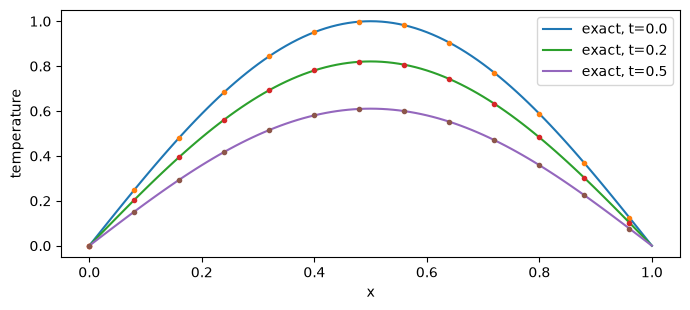

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1501)
alpha = 0.1
width = 80
ax = rng.normal(0, 2, width)
bt = rng.normal(0, 2, width)
bias = rng.normal(0, 1, width)

def features(x, t):
    h = np.tanh(x[:, None]*ax + t[:, None]*bt + bias)
    sech2 = 1 - h*h
    return h, sech2*ax, -2*h*sech2*ax**2, sech2*bt

xc, tc = rng.uniform(0, 1, 700), rng.uniform(0, 0.5, 700)
h, hx, hxx, ht = features(xc, tc)
d, dp = xc[:, None]*(1-xc[:, None]), 1-2*xc[:, None]
A = d*h + tc[:, None]*d*ht
A -= alpha*tc[:, None]*(-2*h + 2*dp*hx + d*hxx)
forcing = alpha*np.pi**2*np.sin(np.pi*xc)
w = np.linalg.lstsq(A, -forcing, rcond=1e-11)[0]

x = np.linspace(0, 1, 101)
errors = []
plt.figure(figsize=(7, 3.2))
for tvalue in [0.0, 0.2, 0.5]:
    t = np.full_like(x, tvalue)
    prediction = np.sin(np.pi*x) + t*x*(1-x)*(features(x, t)[0] @ w)
    exact = np.exp(-alpha*np.pi**2*t)*np.sin(np.pi*x)
    errors.append(np.max(np.abs(prediction-exact)))
    plt.plot(x, exact, label=f"exact, t={tvalue}")
    plt.plot(x[::8], prediction[::8], "o", markersize=3)
assert max(errors) < 0.02
assert np.max(np.abs(A @ w + forcing)) < 0.05
print("Maximum independent-grid errors:", np.array(errors))
plt.xlabel("x"); plt.ylabel("temperature"); plt.legend(); plt.tight_layout(); plt.show()

This test checks the learned field against an exact answer, rather than only checking that optimization decreases a loss. A real unknown problem needs other independent checks: a trusted numerical solution on smaller cases, refined collocation, boundary errors, conservation diagnostics, and stability-based residual estimates. Here a classical sine-series solver is exact and far simpler. The point is to understand the method, not to claim an advantage on a one-dimensional heat equation.

## What does a small residual actually imply?

Let $u$ solve the heat problem and $\widetilde u$ satisfy the same boundary conditions. Set $e=\widetilde u-u$ and $r=\widetilde u_t-\alpha\widetilde u_{xx}$. Then
$e_t-\alpha e_{xx}=r$. Multiply by $e$, integrate over the rod, and integrate by parts. The boundary term vanishes because $e=0$ at both ends:

$$
\frac12\frac{d}{dt}\|e\|_2^2+\alpha\|e_x\|_2^2
=\int er\,dx\leq\|e\|_2\|r\|_2.
$$

Dropping the nonnegative diffusion term gives, when $\|e\|_2>0$,
$d\|e\|_2/dt\leq\|r\|_2$. A limiting argument handles zero norm. Integrating in time yields

$$
\|e(t)\|_2\leq\|e(0)\|_2+\int_0^t\|r(s)\|_2ds.
$$ 

This is a genuine guarantee under the stated smoothness and boundary assumptions. But the training loss samples $r$ at finitely many points, whereas the bound needs a continuum norm. A sharply localized residual between sample points can escape detection. Controlling the gap requires quadrature accuracy, regularity information, or additional analysis. Nonzero boundary errors also add terms and cannot simply be ignored.

For an unstable equation, the corresponding stability constant can grow rapidly. A small residual then may permit a large solution error. For a nonunique PDE, no residual alone selects the physically relevant branch unless appropriate initial, boundary, entropy, or other selection conditions are supplied. The phrase “physics-informed” describes information in the learning construction, not an automatic error certificate.

## Inverse problems and identifiability

Suppose $\alpha$ is unknown. One can train it jointly with $u_\theta$, imposing positivity through $\alpha=e^\eta$ or another positive parameterization. If only the PDE and unspecified initial data are imposed, many values may fit. Even known initial data do not help if they produce a constant solution under insulated boundaries: $u_{xx}=0$ then makes the residual independent of $\alpha$.

For the single sine mode, a noiseless amplitude measurement $A(t)$ gives
$\alpha=-L^2\log[A(t)/A(0)]/(\pi^2t)$ for $t>0$. Its sensitivity is

$$
\frac{\partial u}{\partial\alpha}
=-\left(\frac\pi L\right)^2t\,
e^{-\alpha(\pi/L)^2t}\sin(\pi x/L).
$$

At very short times the sensitivity is small because little diffusion has occurred. At very long times the signal has decayed. For additive measurement noise of fixed variance, the magnitude of this sensitivity is largest around $t=L^2/(\alpha\pi^2)$ and at the antinode $x=L/2$. This is an elementary link between inverse identifiability and experimental design. Different noise models, unknown initial amplitude, or multiple modes change the optimum.

Residual learning can hide parameter errors by changing the field between sensors. Therefore evaluate a **profile loss**: for each candidate $\alpha$, optimize the field and inspect the best loss. A broad minimum indicates weak information. With several unknown parameters, examine the singular values of the observation sensitivity matrix. Near-zero singular values identify combinations that barely affect the data. Regularization or priors can stabilize estimation, but a prior-selected answer should not be called a uniquely data-determined discovery.

## Why training can fail

Differential operators create scale disparities. A spatial error $e_k\sin(kx)$ in a steady diffusion problem produces residual amplitude proportional to $\alpha k^2e_k$. Squaring the residual weights this mode by $\alpha^2k^4$. If represented modes span a wide range of $k$, the least-squares curvature can span many orders of magnitude. The representation and the PDE together determine the conditioning; a network's ability to represent the answer does not imply an optimizer will find it.

Time-dependent problems bring causality. A network fitted over a full space-time region may reduce residuals at late times before accurately establishing the initial state. Time windows or curriculum training can progressively extend the horizon. Stiff reactions, thin boundary layers, shocks, and high-frequency waves can require careful feature scales and sampling. Smooth strong-form networks can smear a discontinuity or produce large derivatives around it.

A **weak formulation** moves derivatives from the represented field to a chosen smooth test function. For the heat equation at a fixed time, multiply the residual by $v(x)$ with $v(0)=v(L)=0$ and integrate:

$$
\begin{aligned}
\int_0^L v(u_t-\alpha u_{xx})\,dx
&=\int_0^L vu_t\,dx
-\alpha[vu_x]_0^L+\alpha\int_0^L v_xu_x\,dx\\
&=\int_0^L vu_t\,dx+\alpha\int_0^L v_xu_x\,dx.
\end{aligned}
$$

The boundary term vanishes by the test function's endpoint values. Setting this expression to zero for every admissible $v$ is the weak equation. Only one spatial derivative of $u$ now appears, rather than two. For smooth fields, integration by parts recovers the strong equation; for less regular fields, the integral identity can remain meaningful even when the ordinary second derivative does not exist. A practical weak residual loss chooses finitely many test functions and numerical quadrature, so its test space and integration accuracy must be checked. Weak forms reduce derivative requirements; they do not automatically supply the physically relevant entropy condition for a shock or resolve nonuniqueness.

Research established concrete gradient imbalances in composite PINN losses [@p-wang2021pathologies] and failures for modest increases in convection, reaction, and diffusion difficulty [@p-krishnapriyan2021]. These are demonstrated failure modes, not proofs that all equation-constrained learning fails. Adaptive loss weighting, causal training, domain decomposition, Fourier features, better optimizers, and hard constraints address different mechanisms. A systematic practical study provides reproducible ablations and strong training baselines [@p-wang2023guide]. No single remedy removes ill-posedness or guarantees efficient solution of arbitrary PDEs.

## How to decide whether this method helps

The original PINN formulation emphasized a flexible combination of differential equations and observations for forward and inverse problems [@p-raissi2019]. That remains an attractive use case when data are irregular, part of the physics is unknown, or an inverse problem couples several data types. For a forward solve on a standard low-dimensional mesh, finite elements, finite volumes, finite differences, and spectral methods are essential baselines. They have mature error analysis, sparse solvers, adaptive meshes, and highly optimized implementations.

Compare total training or optimization cost to the baseline's solve cost at the same observable accuracy. A network's rapid evaluation after expensive fitting is useful when many evaluations of that same fitted field are needed, but does not make the original solve cheap. Report precision, collocation count, optimizer stopping rules, independent solution error, and variations across initializations. An inverse comparison should use the same observations and include a classical adjoint or sensitivity-based fit where feasible.

A promising research direction is hybridization: use a differentiable conventional solver for the well-understood part, represent unknown constitutive relations by a network, and constrain them with symmetry, thermodynamics, and data. Another is certified residual control for regimes with known stability estimates. Both questions focus on the scientific bottleneck: what is unknown, what information constrains it, and what numerical evidence would justify trusting it?

## Implementations to inspect

The [JAX-PI implementation](https://github.com/PredictiveIntelligenceLab/jaxpi) provides research training methods and benchmark examples. The [gradient-pathology study's code](https://github.com/PredictiveIntelligenceLab/GradientPathologiesPINNs) is useful for reproducing loss-balancing experiments. These larger frameworks complement the explicit residual calculation above; they should be approached with a stated equation, nondimensionalization, and independent validation target.

## Exercises and selected answers

1. **Residual by hand.** Insert $u_\theta=Ae^{-bt}\sin\pi x$ into the heat residual on $[0,1]$. Which parameter relation makes it vanish? Which condition fixes $A$?
2. **Hard constraints.** Construct a trial representation for $u(0,t)=1$, $u(1,t)=0$, and $u(x,0)=1-x$. State the compatibility condition at the corners.
3. **An invisible error.** Construct a smooth function whose residual vanishes at a specified finite set of collocation points but is nonzero elsewhere. Explain why adding independent test points helps without proving a uniform bound.
4. **Inverse experiment.** Use the sine-mode sensitivity to choose sensor location and measurement time for estimating diffusivity with fixed additive noise. Then discuss unknown initial amplitude.
5. **Baseline study.** Compare the random-feature code with a centered-difference heat solver. Measure independent errors as spatial resolution and feature count increase. Include training time and the restriction on explicit time steps.

**Answer to 1.** The residual is $A(-b+\alpha\pi^2)e^{-bt}\sin\pi x$, so $b=\alpha\pi^2$ unless $A=0$. The initial condition fixes $A=1$ for the specified initial sine profile. Without it, the zero solution has exactly zero residual.

**Answer to 2.** Use $u_\theta=1-x+t x(1-x)N_\theta(x,t)$. The prescribed initial values at $x=0,1$ match the boundary values at $t=0$, so a continuous solution is possible. More general inconsistent values would obstruct exact continuous corner matching.

**Answer to 4.** With known amplitude and fixed independent additive noise, maximize $|\sin\pi x|$ at $x=1/2$ and $t e^{-\alpha\pi^2t}$ at $t=1/(\alpha\pi^2)$. If the amplitude is also unknown, a single measurement cannot determine both parameters. Measurements at separated times or a separate initial-amplitude measurement supply the missing information.